# Projet EDA — Centre de formation

## Objectif
Tu es Data Analyst dans un centre de formation tunisien. La direction veut comprendre :
- le profil des apprenants ;
- les formations les plus demandées ;
- le chiffre d'affaires et les paiements ;
- l'efficacité des canaux marketing ;
- l'assiduité et les résultats ;
- la satisfaction ;
- les abandons ;
- la performance par formation et formateur.

Le fichier contient volontairement des **valeurs manquantes, doublons, libellés incohérents et anomalies**.

> Conseil : fais d'abord chaque exercice seul(e), puis consulte la correction.


## 1. Importer les bibliothèques et les données
**Exercice :** importer pandas, numpy, matplotlib et seaborn puis lire le CSV.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("/content/sample_data/centre_formation_eda.csv")
df.head()


,student_id,age,gender,city,course,category,trainer,registration_date,start_date,duration_hours,...,price_tnd,discount_tnd,amount_paid,payment_status,attendance_rate,exam_score,completed,satisfaction,marketing_source,registration_status
0,STU0001,20,Femme,Sousse,Power BI,Business Intelligence,Sarra Gharbi,2025-11-05,2025-11-09,30,...,600,150,450.0,Payé,86.1,77.0,Oui,3.9,Recommandation,Terminé
1,STU0002,27,Homme,Tunis,Cybersécurité,IT,Nour Ben Ali,2025-01-21,2025-02-01,48,...,1100,0,1100.0,Payé,79.9,66.9,Oui,NaN,Instagram,Terminé
2,STU0003,28,Femme,Mahdia,Python pour Data,Data,Youssef Trabelsi,2026-01-25,2026-02-18,40,...,900,100,800.0,Payé,26.3,NaN,Non,4.2,Recommandation,Abandonné
3,STU0004,34,Femme,Sousse,Power BI,Business Intelligence,Nour Ben Ali,2025-03-06,2025-04-02,30,...,600,300,200.0,Partiel,75.0,63.6,Oui,4.5,Facebook,Terminé
4,STU0005,22,Homme,Sfax,Intelligence Artificielle,IA,Mehdi Jlassi,2025-04-09,2025-04-23,45,...,1200,100,1100.0,Payé,78.0,71.8,Oui,4.8,Facebook,Terminé


### Explication
- `pandas` sert à manipuler les tableaux de données.
- `numpy` sert aux calculs numériques.
- `matplotlib.pyplot` et `seaborn` servent aux graphiques.
- `pd.read_csv()` transforme le fichier CSV en DataFrame.
- `head()` affiche les 5 premières lignes.


## 2. Comprendre le dataset
**Exercice :** afficher dimensions, colonnes, types, informations générales et statistiques descriptives.

In [ ]:
print("Dimensions :", df.shape)
print("\nColonnes :")
print(df.columns.tolist())

df.info()

df.describe(include="all").T


Dimensions : (525, 21)

Colonnes :
['student_id', 'age', 'gender', 'city', 'course', 'category', 'trainer', 'registration_date', 'start_date', 'duration_hours', 'mode', 'price_tnd', 'discount_tnd', 'amount_paid', 'payment_status', 'attendance_rate', 'exam_score', 'completed', 'satisfaction', 'marketing_source', 'registration_status']
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 525 entries, 0 to 524
Data columns (total 21 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   student_id           525 non-null    object 
 1   age                  525 non-null    int64  
 2   gender               525 non-null    object 
 3   city                 517 non-null    object 
 4   course               525 non-null    object 
 5   category             525 non-null    object 
 6   trainer              525 non-null    object 
 7   registration_date    525 non-null    object 
 8   start_date           525 non-null    object 
 9   dura

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
student_id,525,520,STU0391,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
age,525.0,NaN,NaN,NaN,28.952381,7.108458,18.0,23.0,29.0,33.0,72.0
gender,525,2,Femme,268,NaN,NaN,NaN,NaN,NaN,NaN,NaN
city,517,10,Sousse,159,NaN,NaN,NaN,NaN,NaN,NaN,NaN
course,525,8,Data Analytics,128,NaN,NaN,NaN,NaN,NaN,NaN,NaN
category,525,7,Data,198,NaN,NaN,NaN,NaN,NaN,NaN,NaN
trainer,525,6,Amira Ben Salem,101,NaN,NaN,NaN,NaN,NaN,NaN,NaN
registration_date,525,338,2026-03-26,5,NaN,NaN,NaN,NaN,NaN,NaN,NaN
start_date,525,359,2025-10-12,4,NaN,NaN,NaN,NaN,NaN,NaN,NaN
duration_hours,525.0,NaN,NaN,NaN,48.041905,17.020928,24.0,30.0,45.0,60.0,72.0


### À observer
`shape` répond à : combien de lignes et de colonnes avons-nous ?  
`info()` permet de repérer les types et les valeurs manquantes.  
`describe()` permet notamment d'observer moyenne, écart-type, minimum, maximum et quartiles.

Un maximum impossible, par exemple un taux de présence supérieur à 100 %, doit attirer ton attention.


## 3. Rechercher les valeurs manquantes

In [ ]:
missing = df.isnull().sum().sort_values(ascending=False)
missing_percent = (df.isnull().mean() * 100).round(2)

missing_table = pd.DataFrame({
    "Valeurs manquantes": missing,
    "Pourcentage": missing_percent
}).sort_values("Valeurs manquantes", ascending=False)

missing_table


,Valeurs manquantes,Pourcentage
exam_score,41,7.81
satisfaction,12,2.29
city,8,1.52
marketing_source,6,1.14
age,0,0.00
category,0,0.00
attendance_rate,0,0.00
amount_paid,0,0.00
completed,0,0.00
duration_hours,0,0.00


### Explication
`isnull()` transforme chaque cellule en True/False selon qu'elle est vide.  
`sum()` compte les True colonne par colonne.  
`mean()*100` donne le pourcentage de données manquantes.

Attention : un `exam_score` vide peut être logique pour un apprenant qui a abandonné ou n'a pas encore passé son examen. Il ne faut donc pas remplir automatiquement toutes les valeurs manquantes.


## 4. Rechercher et supprimer les doublons

In [ ]:
print("Nombre de lignes dupliquées :", df.duplicated().sum())

df[df.duplicated(keep=False)].sort_values("student_id").head(15)


Nombre de lignes dupliquées : 5


,student_id,age,gender,city,course,category,trainer,registration_date,start_date,duration_hours,...,price_tnd,discount_tnd,amount_paid,payment_status,attendance_rate,exam_score,completed,satisfaction,marketing_source,registration_status
24,STU0025,33,Femme,Tunis,Power BI,Business Intelligence,Ahmed Mansour,2026-01-31,2026-02-11,30,...,600,200,400.0,Payé,52.7,63.7,Oui,4.1,Facebook,Terminé
524,STU0025,33,Femme,Tunis,Power BI,Business Intelligence,Ahmed Mansour,2026-01-31,2026-02-11,30,...,600,200,400.0,Payé,52.7,63.7,Oui,4.1,Facebook,Terminé
296,STU0297,31,Homme,Tunis,Data Analytics,Data,Youssef Trabelsi,2026-01-18,2026-02-08,72,...,1800,0,1800.0,Payé,83.8,75.4,Oui,4.1,Recommandation,Terminé
522,STU0297,31,Homme,Tunis,Data Analytics,Data,Youssef Trabelsi,2026-01-18,2026-02-08,72,...,1800,0,1800.0,Payé,83.8,75.4,Oui,4.1,Recommandation,Terminé
390,STU0391,35,Femme,Sousse,Intelligence Artificielle,IA,Amira Ben Salem,2026-05-11,2026-05-20,45,...,1200,50,1150.0,Payé,66.6,57.7,Oui,3.8,Événement,Terminé
521,STU0391,35,Femme,Sousse,Intelligence Artificielle,IA,Amira Ben Salem,2026-05-11,2026-05-20,45,...,1200,50,1150.0,Payé,66.6,57.7,Oui,3.8,Événement,Terminé
446,STU0447,23,Femme,Mahdia,Data Analytics,Data,Sarra Gharbi,2025-01-10,2025-01-29,72,...,1800,200,1600.0,Payé,71.8,77.3,Oui,3.4,Recommandation,Terminé
520,STU0447,23,Femme,Mahdia,Data Analytics,Data,Sarra Gharbi,2025-01-10,2025-01-29,72,...,1800,200,1600.0,Payé,71.8,77.3,Oui,3.4,Recommandation,Terminé
456,STU0457,35,Homme,Monastir,Power BI,Business Intelligence,Amira Ben Salem,2026-04-13,2026-04-17,30,...,600,0,600.0,Payé,74.6,70.8,Oui,4.9,Recommandation,Terminé
523,STU0457,35,Homme,Monastir,Power BI,Business Intelligence,Amira Ben Salem,2026-04-13,2026-04-17,30,...,600,0,600.0,Payé,74.6,70.8,Oui,4.9,Recommandation,Terminé


In [ ]:
df = df.drop_duplicates().copy()
print("Dimensions après suppression :", df.shape)


Dimensions après suppression : (520, 21)


## 5. Corriger les catégories incohérentes

In [ ]:
print(df["city"].value_counts(dropna=False))
print(df["mode"].value_counts(dropna=False))


city
Sousse         158
Tunis          102
Monastir        74
Sidi Bouzid     47
Sfax            46
Kairouan        34
Mahdia          25
Nabeul          24
NaN              8
sousse           1
SOUSSE           1
Name: count, dtype: int64
mode
Présentiel    236
En ligne      197
Hybride        86
Online          1
Name: count, dtype: int64


In [ ]:
df["city"] = df["city"].replace({
    "sousse": "Sousse",
    "SOUSSE": "Sousse"
})

df["mode"] = df["mode"].replace({
    "Online": "En ligne"
})


La même catégorie écrite différemment serait considérée comme plusieurs catégories par Python. Il faut donc standardiser les libellés.

## 6. Conversion des dates

In [ ]:
df["registration_date"] = pd.to_datetime(df["registration_date"])
df["start_date"] = pd.to_datetime(df["start_date"])

df["registration_year"] = df["registration_date"].dt.year
df["registration_month"] = df["registration_date"].dt.to_period("M").astype(str)

df[["registration_date","registration_year","registration_month"]].head()


,registration_date,registration_year,registration_month
0,2025-11-05,2025,2025-11
1,2025-01-21,2025,2025-01
2,2026-01-25,2026,2026-01
3,2025-03-06,2025,2025-03
4,2025-04-09,2025,2025-04


## 7. Détecter les anomalies métier

In [ ]:
print("Âges suspects :")
print(df[(df["age"] < 18) | (df["age"] > 60)][["student_id","age"]])

print("\nPrésences impossibles :")
print(df[(df["attendance_rate"] < 0) | (df["attendance_rate"] > 100)]
      [["student_id","attendance_rate"]])

print("\nRemises supérieures au prix :")
print(df[df["discount_tnd"] > df["price_tnd"]]
      [["student_id","course","price_tnd","discount_tnd"]])


Âges suspects :
  student_id  age
5    STU0006   72

Présences impossibles :
   student_id  attendance_rate
44    STU0045            115.0

Remises supérieures au prix :
Empty DataFrame
Columns: [student_id, course, price_tnd, discount_tnd]
Index: []


In [ ]:
# Corrections métier
df.loc[df["attendance_rate"] > 100, "attendance_rate"] = 100

# Une remise ne peut pas dépasser le prix.
df.loc[df["discount_tnd"] > df["price_tnd"], "discount_tnd"] = df["price_tnd"]

# L'âge 72 est conservé ici : rare ne signifie pas forcément faux.
# Dans un vrai projet, on demanderait une vérification à la source.


### Point important
Un outlier n'est pas automatiquement une erreur. Un apprenant de 72 ans est inhabituel mais possible.  
En revanche, une présence de 115 % est incompatible avec la définition du KPI : elle doit être vérifiée/corrigée.


## 8. Créer des KPIs utiles

In [ ]:
df["net_price"] = df["price_tnd"] - df["discount_tnd"]
df["remaining_balance"] = df["net_price"] - df["amount_paid"]

print("Nombre d'inscriptions :", len(df))
print("Apprenants uniques :", df["student_id"].nunique())
print("Montant encaissé :", round(df["amount_paid"].sum(), 2), "TND")
print("Montant restant :", round(df["remaining_balance"].sum(), 2), "TND")
print("Présence moyenne :", round(df["attendance_rate"].mean(), 2), "%")
print("Score moyen :", round(df["exam_score"].mean(), 2))
print("Satisfaction moyenne :", round(df["satisfaction"].mean(), 2), "/ 5")
print("Taux d'abandon :", round((df["registration_status"].eq("Abandonné").mean()*100),2), "%")


Nombre d'inscriptions : 520
Apprenants uniques : 520
Montant encaissé : 446950.0 TND
Montant restant : 52750.0 TND
Présence moyenne : 77.09 %
Score moyen : 74.14
Satisfaction moyenne : 4.05 / 5
Taux d'abandon : 11.35 %


## 9. Chart 1 — Nombre d'inscriptions par formation

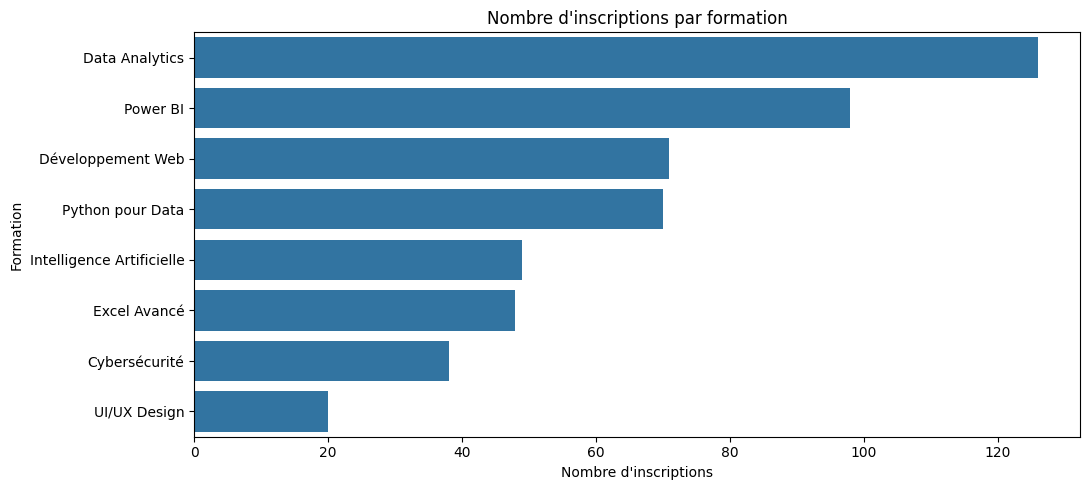

In [ ]:
course_counts = df["course"].value_counts()

plt.figure(figsize=(11,5))
sns.barplot(x=course_counts.values, y=course_counts.index)
plt.title("Nombre d'inscriptions par formation")
plt.xlabel("Nombre d'inscriptions")
plt.ylabel("Formation")
plt.tight_layout()
plt.show()


**Interprétation :** le graphique permet d'identifier les formations qui attirent le plus d'apprenants et d'aider la direction à planifier les sessions et les formateurs.

## 10. Chart 2 — Évolution mensuelle des inscriptions

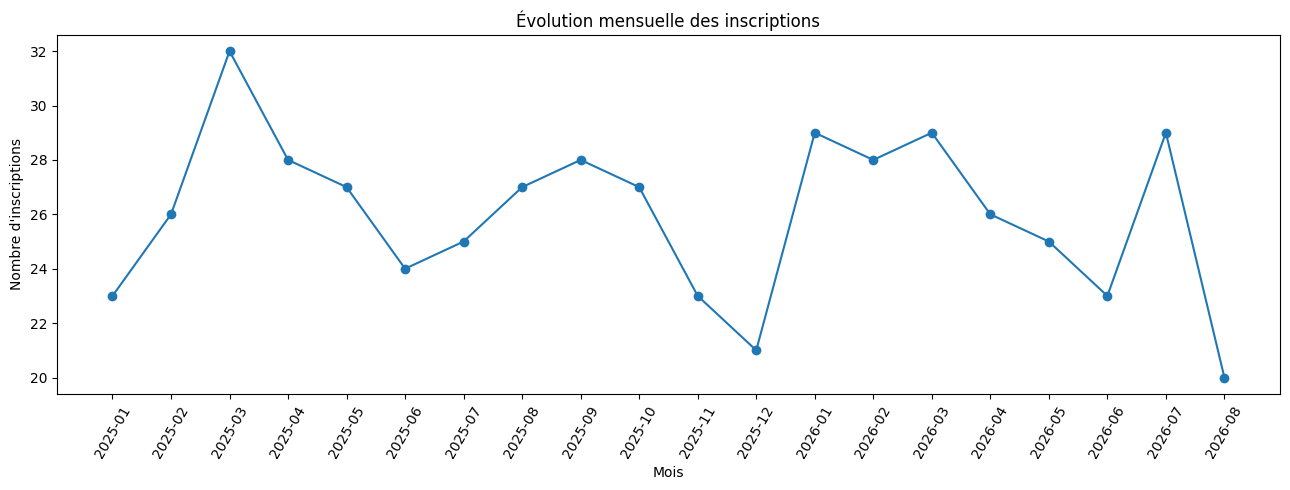

In [ ]:
monthly = df.groupby("registration_month").size()

plt.figure(figsize=(13,5))
plt.plot(monthly.index, monthly.values, marker="o")
plt.title("Évolution mensuelle des inscriptions")
plt.xlabel("Mois")
plt.ylabel("Nombre d'inscriptions")
plt.xticks(rotation=60)
plt.tight_layout()
plt.show()


Ce graphique permet d'identifier une tendance, des pics saisonniers ou des périodes faibles.

## 11. Chart 3 — Montants encaissés par formation

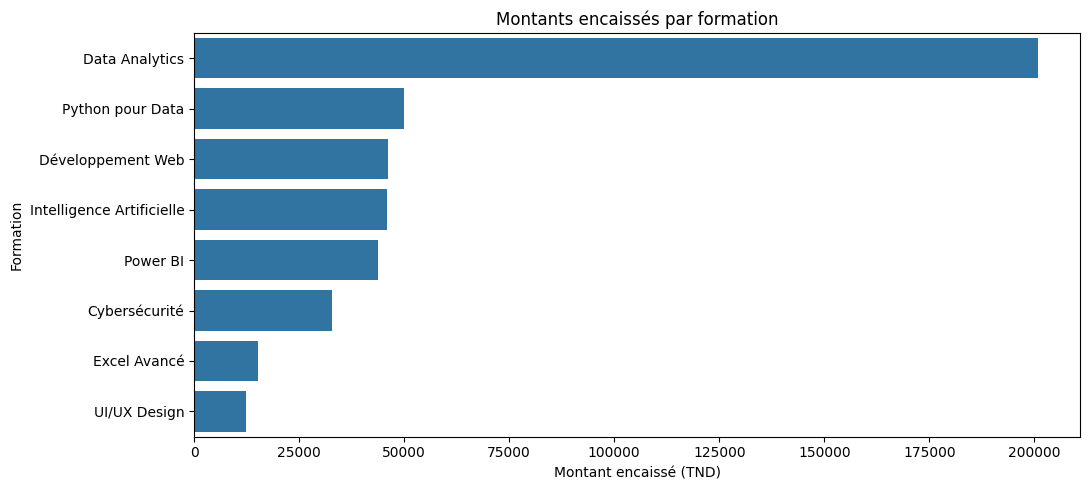

In [ ]:
revenue_course = (
    df.groupby("course")["amount_paid"]
      .sum()
      .sort_values(ascending=False)
)

plt.figure(figsize=(11,5))
sns.barplot(x=revenue_course.values, y=revenue_course.index)
plt.title("Montants encaissés par formation")
plt.xlabel("Montant encaissé (TND)")
plt.ylabel("Formation")
plt.tight_layout()
plt.show()


Une formation très populaire n'est pas forcément celle qui génère le plus de revenus : son prix joue aussi un rôle.

## 12. Chart 4 — Répartition géographique

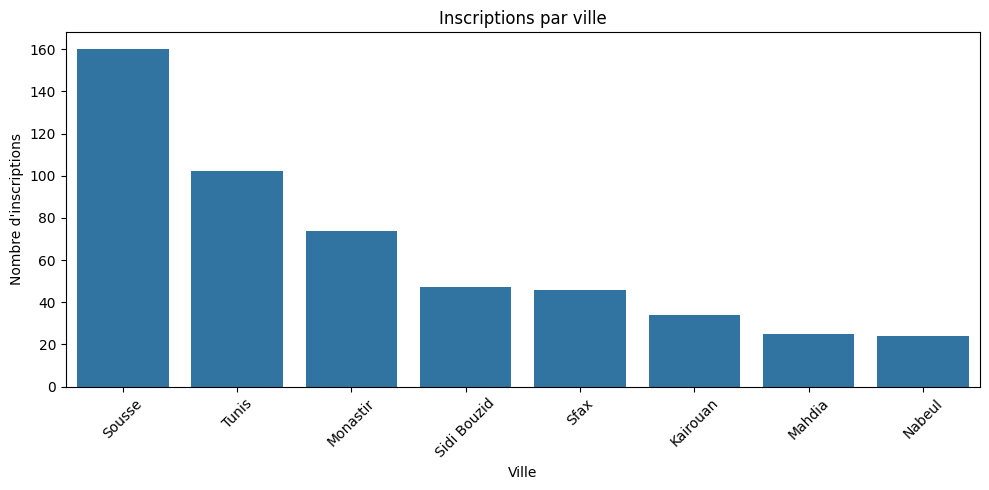

In [ ]:
city_counts = df["city"].value_counts()

plt.figure(figsize=(10,5))
sns.barplot(x=city_counts.index, y=city_counts.values)
plt.title("Inscriptions par ville")
plt.xlabel("Ville")
plt.ylabel("Nombre d'inscriptions")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


## 13. Chart 5 — Sources marketing

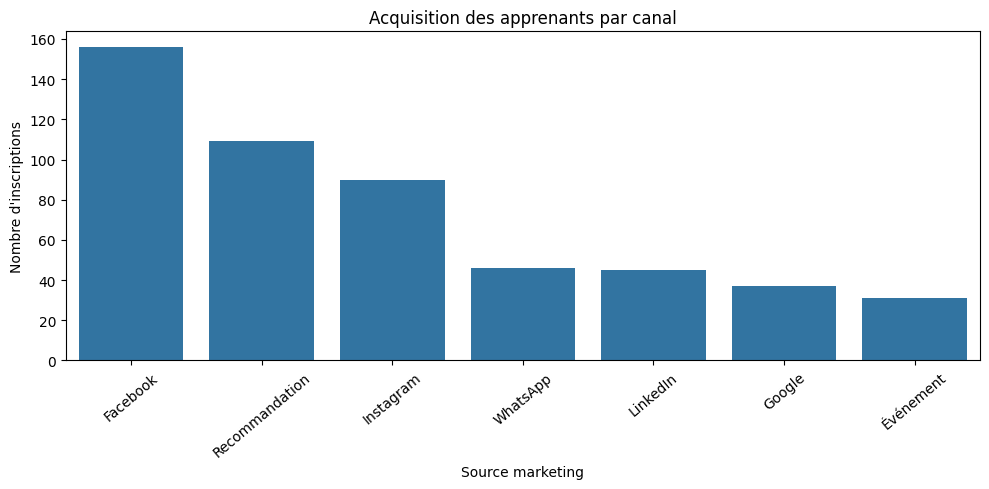

In [ ]:
source_counts = df["marketing_source"].value_counts()

plt.figure(figsize=(10,5))
sns.barplot(x=source_counts.index, y=source_counts.values)
plt.title("Acquisition des apprenants par canal")
plt.xlabel("Source marketing")
plt.ylabel("Nombre d'inscriptions")
plt.xticks(rotation=40)
plt.tight_layout()
plt.show()


Ce graphique mesure ici le **volume d'inscriptions attribué à chaque canal**, pas le ROI marketing. Pour calculer un vrai ROI, il faudrait également disposer du coût publicitaire de chaque canal.


## 14. Chart 6 — Modes de formation

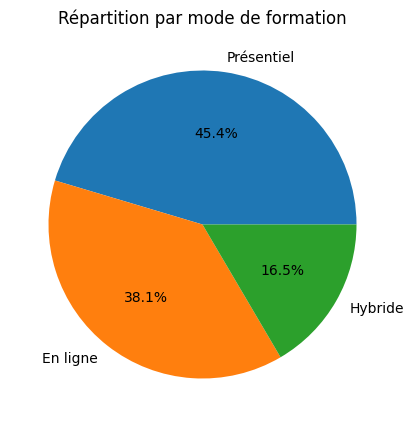

In [ ]:
mode_counts = df["mode"].value_counts()

plt.figure(figsize=(7,5))
plt.pie(mode_counts.values, labels=mode_counts.index, autopct="%1.1f%%")
plt.title("Répartition par mode de formation")
plt.show()


## 15. Chart 7 — Distribution des âges

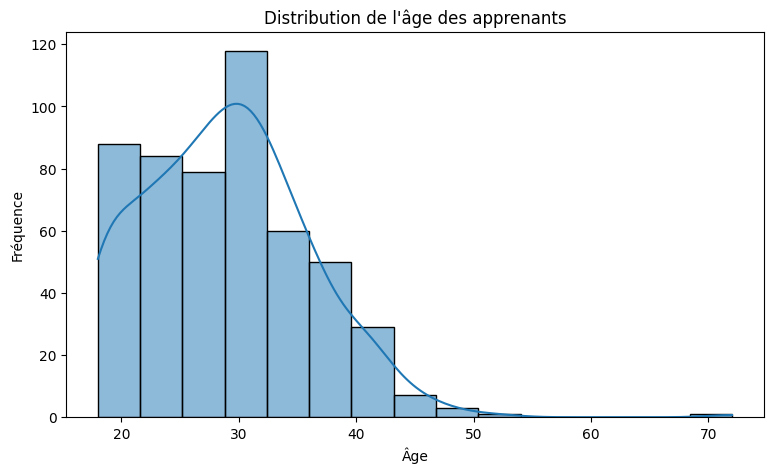

In [ ]:
plt.figure(figsize=(9,5))
sns.histplot(data=df, x="age", bins=15, kde=True)
plt.title("Distribution de l'âge des apprenants")
plt.xlabel("Âge")
plt.ylabel("Fréquence")
plt.show()


L'histogramme montre comment les âges sont distribués. La courbe KDE donne une représentation lissée de cette distribution.

## 16. Chart 8 — Distribution des scores

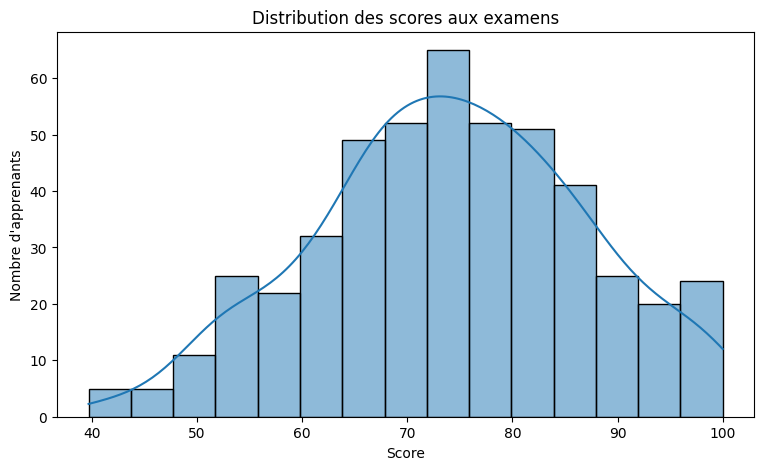

In [ ]:
plt.figure(figsize=(9,5))
sns.histplot(data=df, x="exam_score", bins=15, kde=True)
plt.title("Distribution des scores aux examens")
plt.xlabel("Score")
plt.ylabel("Nombre d'apprenants")
plt.show()


## 17. Chart 9 — Présence vs résultat

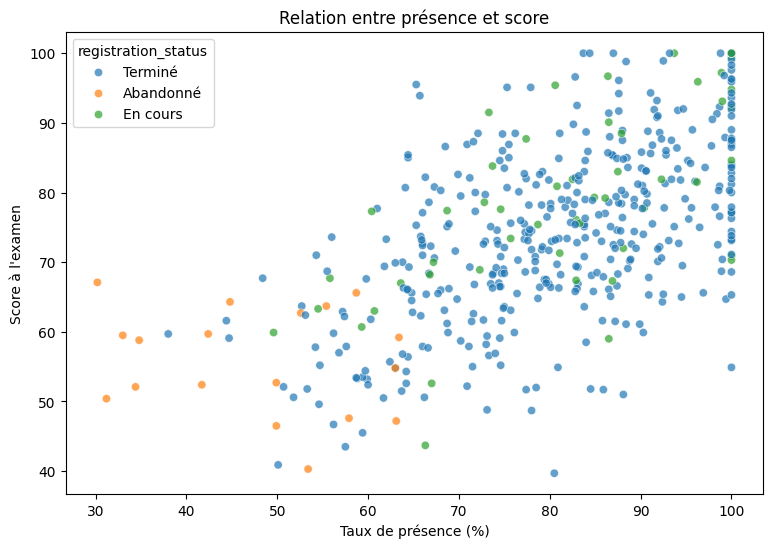

Corrélation : 0.601


In [ ]:
plt.figure(figsize=(9,6))
sns.scatterplot(data=df, x="attendance_rate", y="exam_score",
                hue="registration_status", alpha=0.7)
plt.title("Relation entre présence et score")
plt.xlabel("Taux de présence (%)")
plt.ylabel("Score à l'examen")
plt.show()

print("Corrélation :",
      round(df[["attendance_rate","exam_score"]].corr().iloc[0,1], 3))


### Interprétation
Chaque point représente un apprenant. Si le nuage monte globalement de gauche à droite, présence et score sont positivement associés.

**Attention : corrélation ≠ causalité.** Une association ne prouve pas que la présence est l'unique cause d'un meilleur score.


## 18. Chart 10 — Satisfaction par formation

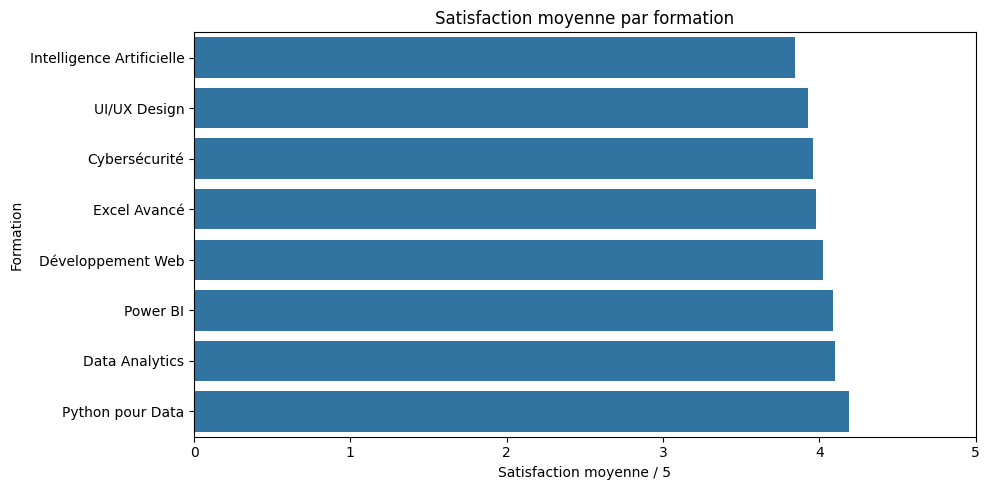

In [ ]:
satisfaction_course = (
    df.groupby("course")["satisfaction"]
      .mean()
      .sort_values()
)

plt.figure(figsize=(10,5))
sns.barplot(x=satisfaction_course.values, y=satisfaction_course.index)
plt.title("Satisfaction moyenne par formation")
plt.xlabel("Satisfaction moyenne / 5")
plt.ylabel("Formation")
plt.xlim(0,5)
plt.tight_layout()
plt.show()


## 19. Chart 11 — Boxplot des scores par formation

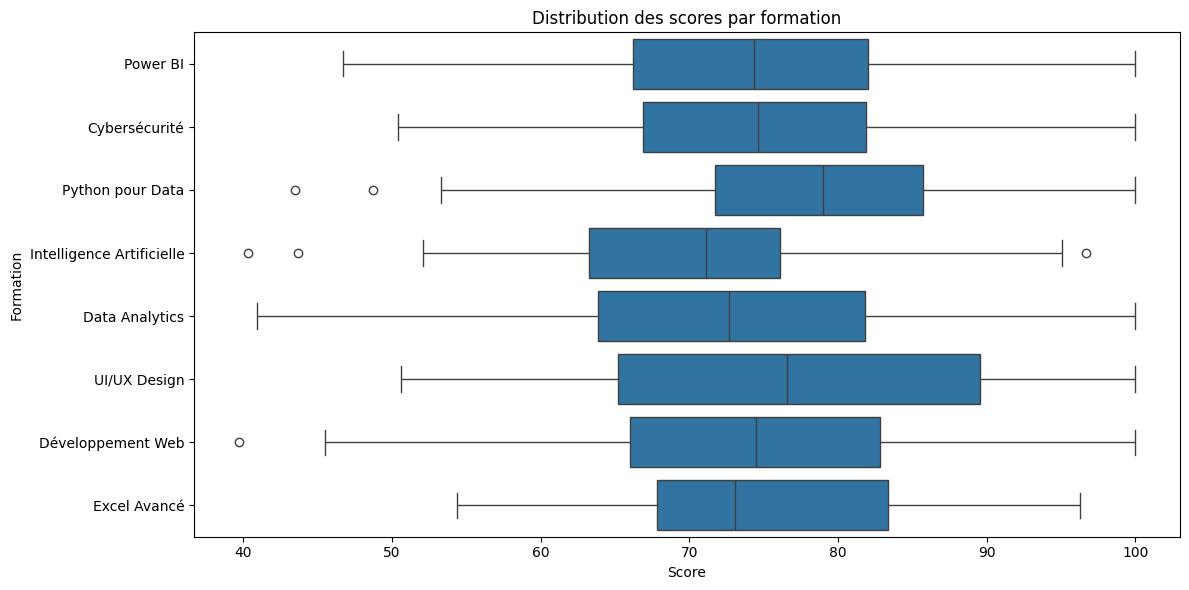

In [ ]:
plt.figure(figsize=(12,6))
sns.boxplot(data=df, x="exam_score", y="course")
plt.title("Distribution des scores par formation")
plt.xlabel("Score")
plt.ylabel("Formation")
plt.tight_layout()
plt.show()


Le boxplot permet de comparer médiane, dispersion et valeurs extrêmes entre les formations.

## 20. Chart 12 — Performance des formateurs

In [ ]:
trainer_perf = (
    df.groupby("trainer")
      .agg(
          nb_apprenants=("student_id","count"),
          satisfaction_moyenne=("satisfaction","mean"),
          score_moyen=("exam_score","mean"),
          presence_moyenne=("attendance_rate","mean")
      )
      .sort_values("satisfaction_moyenne", ascending=False)
)

trainer_perf.round(2)


,nb_apprenants,satisfaction_moyenne,score_moyen,presence_moyenne
trainer,,,,
Sarra Gharbi,96,4.22,74.54,78.39
Ahmed Mansour,82,4.10,75.62,78.82
Nour Ben Ali,78,4.08,74.34,75.15
Youssef Trabelsi,72,3.99,74.21,75.54
Mehdi Jlassi,93,3.96,74.11,78.48
Amira Ben Salem,99,3.93,72.34,75.75


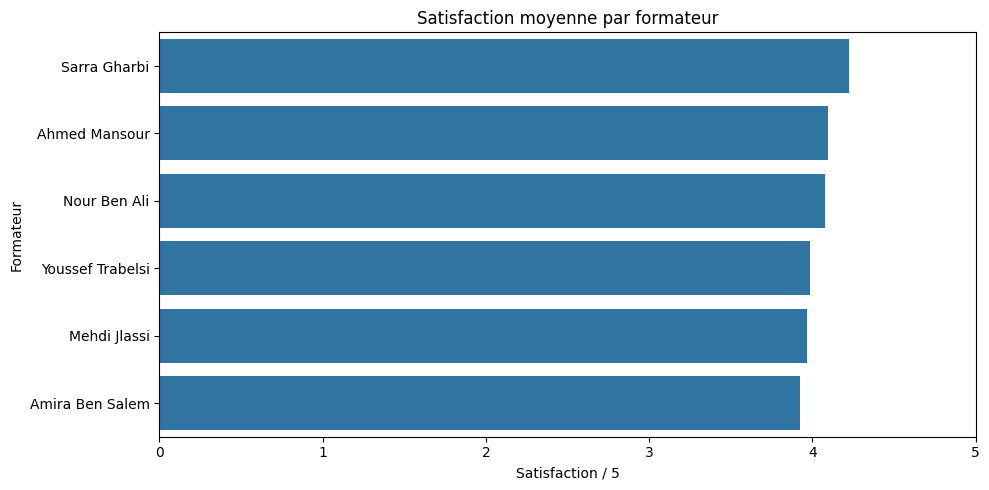

In [ ]:
plt.figure(figsize=(10,5))
sns.barplot(data=trainer_perf.reset_index(),
            x="satisfaction_moyenne", y="trainer")
plt.title("Satisfaction moyenne par formateur")
plt.xlabel("Satisfaction / 5")
plt.ylabel("Formateur")
plt.xlim(0,5)
plt.tight_layout()
plt.show()


Attention à ne pas conclure qu'un formateur est meilleur uniquement sur cette moyenne : niveau des groupes, formation enseignée et taille d'échantillon peuvent influencer le résultat.

## 21. Chart 13 — Statut de paiement

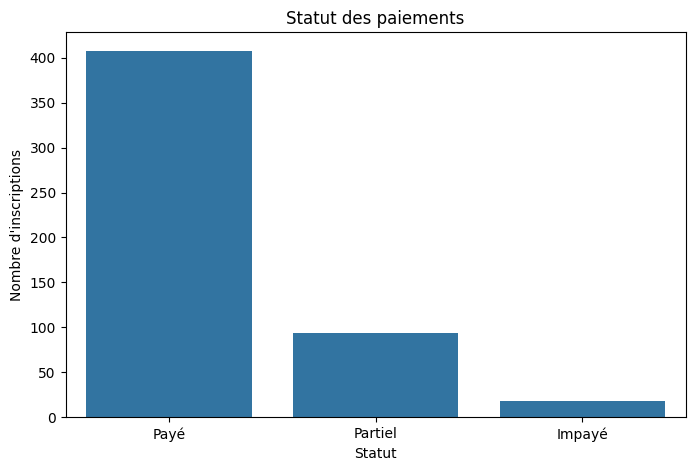

In [ ]:
payment_counts = df["payment_status"].value_counts()

plt.figure(figsize=(8,5))
sns.barplot(x=payment_counts.index, y=payment_counts.values)
plt.title("Statut des paiements")
plt.xlabel("Statut")
plt.ylabel("Nombre d'inscriptions")
plt.show()


## 22. Chart 14 — Taux d'abandon par formation

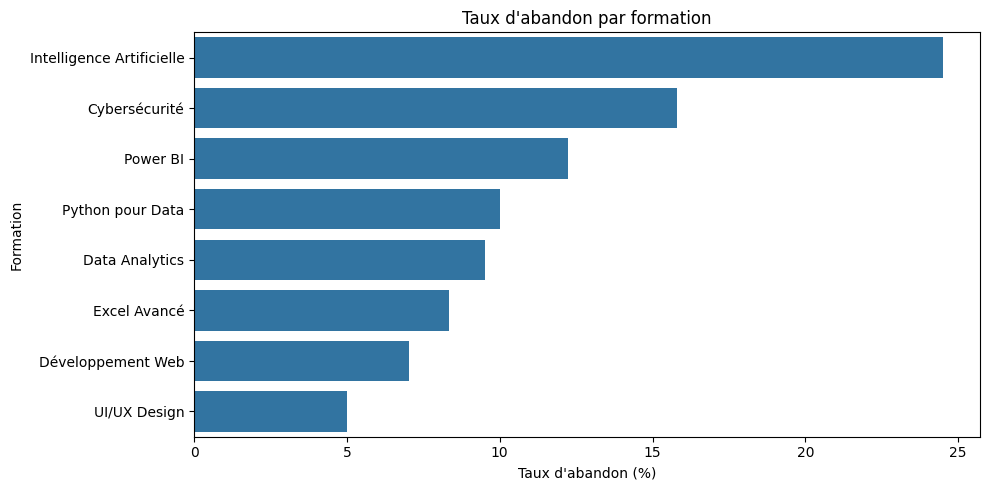

In [ ]:
abandon = (
    df.assign(is_dropout=df["registration_status"].eq("Abandonné"))
      .groupby("course")["is_dropout"]
      .mean()
      .mul(100)
      .sort_values(ascending=False)
)

plt.figure(figsize=(10,5))
sns.barplot(x=abandon.values, y=abandon.index)
plt.title("Taux d'abandon par formation")
plt.xlabel("Taux d'abandon (%)")
plt.ylabel("Formation")
plt.tight_layout()
plt.show()


## 23. Chart 15 — Heatmap des corrélations

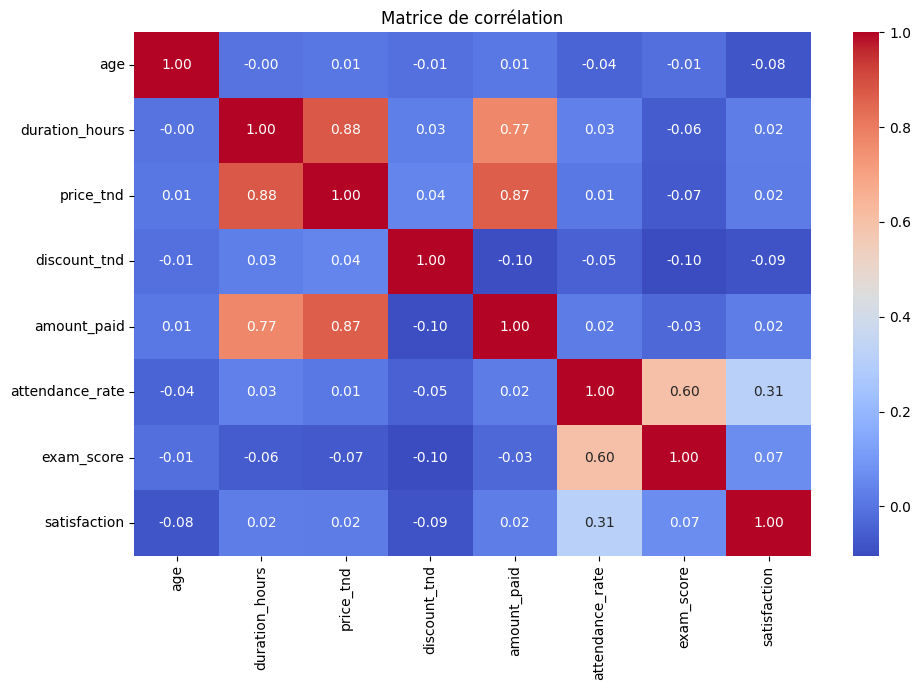

In [ ]:
numeric_cols = [
    "age", "duration_hours", "price_tnd", "discount_tnd",
    "amount_paid", "attendance_rate", "exam_score", "satisfaction"
]

corr = df[numeric_cols].corr()

plt.figure(figsize=(10,7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Matrice de corrélation")
plt.tight_layout()
plt.show()


Une corrélation proche de +1 indique une relation linéaire positive forte ; proche de -1 une relation négative forte ; proche de 0 indique peu de relation linéaire. Encore une fois, elle ne démontre pas une causalité.


# 24. Questions métier finales

Réponds à ces questions avant de regarder tes résultats :

1. Quelle formation possède le plus d'inscriptions ?
2. Quelle formation génère le plus de montant encaissé ?
3. Quelle ville contient le plus d'apprenants ?
4. Quel canal marketing apporte le plus d'inscriptions ?
5. Quel est le taux d'abandon global ?
6. Quelles formations ont les taux d'abandon les plus élevés ?
7. Quel est le taux moyen de présence ?
8. Existe-t-il une relation entre présence et résultat ?
9. Quelle formation possède la meilleure satisfaction moyenne ?
10. Combien reste-t-il à encaisser ?
11. Quels mois ont enregistré le plus d'inscriptions ?
12. Quels segments mériteraient une investigation supplémentaire ?

## Conclusion attendue
Une bonne EDA ne consiste pas seulement à produire des graphiques. Pour chaque graphique, formule :
**Observation → hypothèse → vérification supplémentaire → éventuelle action métier.**
